<a href="https://colab.research.google.com/github/Ekimxii/fitness_pose_tracker/blob/karen-pose-detection/pose-detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
path = kagglehub.dataset_download("muhannadtuameh/exercise-recognition")
print(path)

100%|██████████| 1.07M/1.07M [00:00<00:00, 55.4MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/muhannadtuameh/exercise-recognition/versions/5


In [2]:
import pandas as pd

names = ["labels", "landmarks", "angles", "3d_distances", "xyz_distances"]
dfs = {n: pd.read_csv(f"{path}/{n}.csv") for n in names}
for n, df in dfs.items():
    print(f"{n:14} {df.shape}  {list(df.columns[:4])}")

# All five files share one ID column; find it instead of guessing its name
shared = set.intersection(*(set(df.columns) for df in dfs.values()))
assert len(shared) == 1, f"Expected one shared ID column, got {shared}"
ID = shared.pop()
LABEL = [c for c in dfs["labels"].columns if c != ID][0]

# Join into one table, one row per frame; validate= stops with an error if an ID repeats
data = dfs["labels"]
for n in names[1:]:
    data = data.merge(dfs[n], on=ID, validate="one_to_one", suffixes=("", f"_{n}"))
print("ID:", ID, "| label:", LABEL, "| merged:", data.shape)

labels         (1372, 2)  ['pose_id', 'pose']
landmarks      (1372, 100)  ['pose_id', 'x_nose', 'y_nose', 'z_nose']
angles         (1372, 8)  ['pose_id', 'right_elbow_right_shoulder_right_hip', 'left_elbow_left_shoulder_left_hip', 'right_knee_mid_hip_left_knee']
3d_distances   (1372, 17)  ['pose_id', 'left_shoulder_left_wrist', 'right_shoulder_right_wrist', 'left_hip_left_ankle']
xyz_distances  (1372, 49)  ['pose_id', 'x_left_shoulder_left_wrist', 'y_left_shoulder_left_wrist', 'z_left_shoulder_left_wrist']
ID: pose_id | label: pose | merged: (1372, 172)


In [3]:
print("missing values:", data.isna().sum().sum())
print(data[LABEL].value_counts())   # expect 10 classes: 5 exercises × up/down

# Split each label into exercise + position
data["position"] = data[LABEL].str.extract(r"(up|down)$", expand=False)
data["exercise"] = data[LABEL].str.replace(r"_?(up|down)$", "", regex=True)
pd.crosstab(data["exercise"], data["position"])

missing values: 0
pose
jumping_jacks_down    189
jumping_jacks_up      181
pullups_down          154
pushups_up            144
squats_up             139
pullups_up            135
squats_down           127
pushups_down          102
situp_down            102
situp_up               99
Name: count, dtype: int64


position,down,up
exercise,,
jumping_jacks,189,181
pullups,154,135
pushups,102,144
situp,102,99
squats,127,139


In [4]:
data.head(10)

,pose_id,pose,x_nose,y_nose,z_nose,x_left_eye_inner,y_left_eye_inner,z_left_eye_inner,x_left_eye,y_left_eye,...,y_left_ankle_right_ankle,z_left_ankle_right_ankle,x_left_hip_avg_left_wrist_left_ankle,y_left_hip_avg_left_wrist_left_ankle,z_left_hip_avg_left_wrist_left_ankle,x_right_hip_avg_right_wrist_right_ankle,y_right_hip_avg_right_wrist_right_ankle,z_right_hip_avg_right_wrist_right_ankle,position,exercise
0,0,jumping_jacks_down,-5.889507,-57.637520,-45.019750,-4.656085,-62.832863,-44.571823,-3.302626,-63.386856,...,0.212624,-5.843784,-3.219780,-15.325796,-19.404337,1.893529,-16.874212,-13.826653,down,jumping_jacks
1,1,jumping_jacks_down,-4.255504,-62.935925,-128.907500,-2.977403,-67.035990,-124.258545,-2.215265,-67.198250,...,-1.001450,7.225679,-3.736290,-35.671420,61.273800,6.796126,-35.755894,55.422730,down,jumping_jacks
2,2,jumping_jacks_down,-2.878917,-61.709988,-137.453340,-1.619050,-65.693750,-132.181660,-0.785822,-65.814340,...,-1.760807,4.617828,-4.954575,-35.918790,66.473480,7.703906,-34.360416,64.989730,down,jumping_jacks
3,3,jumping_jacks_down,-4.242575,-60.371220,-135.094830,-3.118133,-64.416000,-129.995930,-2.369744,-64.603290,...,0.139687,8.158640,-6.365989,-31.441952,51.794930,10.238924,-34.275177,47.919495,down,jumping_jacks
4,4,jumping_jacks_down,-0.805543,-56.178570,-41.124413,-0.055174,-58.501305,-37.938560,0.456936,-58.473960,...,0.822025,-0.946480,-5.459134,-18.484953,-13.069115,5.099875,-18.971666,-0.777858,down,jumping_jacks
5,5,jumping_jacks_down,-1.453686,-55.868320,-49.871550,-0.738563,-58.564365,-46.533375,-0.246085,-58.588676,...,-1.544949,2.431656,-1.908938,-17.136877,-17.229788,3.006621,-16.279325,-7.491985,down,jumping_jacks
6,6,jumping_jacks_down,-1.413537,-56.764880,-53.314358,-0.619420,-59.054150,-50.608140,-0.082197,-59.036785,...,1.487221,-2.058857,-2.129393,-21.129667,-9.891249,2.195711,-22.089981,-11.886066,down,jumping_jacks
7,7,jumping_jacks_down,-1.038447,-56.668972,-55.748825,-0.259608,-59.307420,-52.662563,0.300576,-59.309590,...,-0.029747,-3.641392,-1.937086,-19.413795,-14.534452,3.026950,-19.955368,-13.444800,down,jumping_jacks
8,8,jumping_jacks_down,-0.923746,-61.599230,-42.670067,0.066155,-63.556183,-39.227818,0.691268,-63.524258,...,0.012642,5.808826,-2.134404,-25.914886,-0.918108,1.588044,-27.323212,-4.747983,down,jumping_jacks
9,9,jumping_jacks_down,-1.278404,-60.812294,-43.952213,-0.183104,-62.631630,-40.798725,0.446046,-62.604500,...,-0.939735,2.423367,-1.613915,-26.098032,-6.020682,1.928428,-27.536129,-7.286598,down,jumping_jacks




```
`# This is formatted as code`
```

## Visualizations

How many frames each class has, how joint angles differ between poses, and how much they vary within each pose. Colors match across charts: **up = blue, down = orange**.

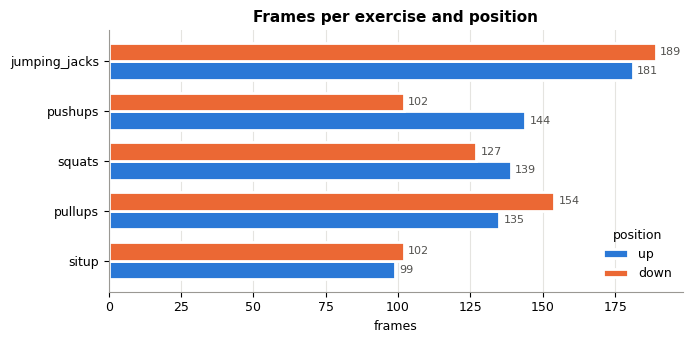

In [5]:
import matplotlib.pyplot as plt

# Shared look for every chart below: up = blue, down = orange, light grid, no box
POS_COLORS = {"up": "#2a78d6", "down": "#eb6834"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": "#9a9893",
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
})

# 1. Class balance: frames per exercise, split by position
counts = pd.crosstab(data["exercise"], data["position"])[["up", "down"]]
ax = counts.sort_values("up").plot.barh(
    color=POS_COLORS, width=0.75, edgecolor="white", linewidth=2, figsize=(7, 3.5))
for bars in ax.containers:
    ax.bar_label(bars, padding=3, fontsize=8, color="#52514e")
ax.set(title="Frames per exercise and position", xlabel="frames", ylabel="")
ax.grid(axis="y", visible=False)
ax.legend(title="position", frameon=False)
plt.tight_layout()

Each cell is the average angle (in degrees) at one joint for one pose. Large

1.   List item
2.   List item

differences between a pose's up and down rows show which joints a classifier can rely on: shoulders for jumping jacks and pull-ups, knees for squats, elbows for push-ups.

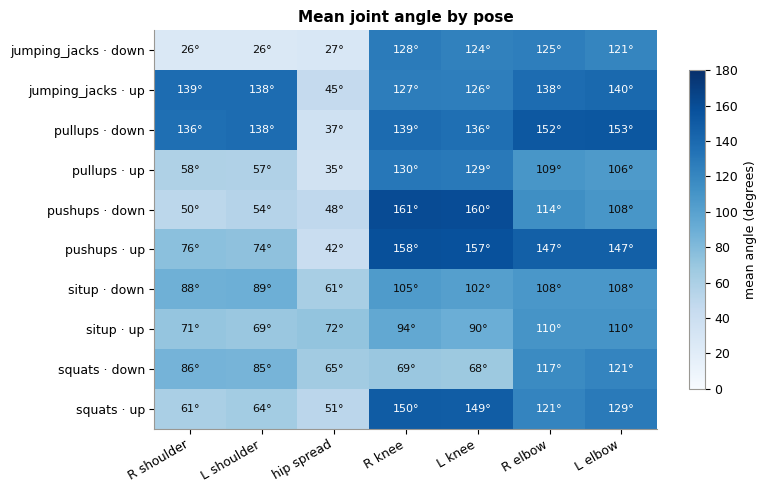

In [6]:
# 2. Average joint angle for each pose: which joints separate the classes?
angle_cols = list(dfs["angles"].columns.drop(ID))
short = {  # the middle joint is the vertex of each angle
    "right_elbow_right_shoulder_right_hip": "R shoulder",
    "left_elbow_left_shoulder_left_hip": "L shoulder",
    "right_knee_mid_hip_left_knee": "hip spread",
    "right_hip_right_knee_right_ankle": "R knee",
    "left_hip_left_knee_left_ankle": "L knee",
    "right_wrist_right_elbow_right_shoulder": "R elbow",
    "left_wrist_left_elbow_left_shoulder": "L elbow",
}
mean_angles = (data.groupby(["exercise", "position"])[angle_cols].mean()
               .rename(columns=short))

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(mean_angles, cmap="Blues", vmin=0, vmax=180, aspect="auto")
ax.set_xticks(range(mean_angles.shape[1]), mean_angles.columns, rotation=30, ha="right")
ax.set_yticks(range(len(mean_angles)), [f"{e} · {p}" for e, p in mean_angles.index])
ax.grid(False)
for (r, c), v in pd.DataFrame(mean_angles.values).stack().items():
    ax.text(c, r, f"{v:.0f}°", ha="center", va="center", fontsize=8,
            color="white" if v > 110 else "#0b0b0b")
fig.colorbar(im, ax=ax, label="mean angle (degrees)", shrink=0.8)
ax.set_title("Mean joint angle by pose")
plt.tight_layout()